In [10]:
from pathlib import Path
import json
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import(average_precision_score, roc_auc_score, f1_score, precision_score, recall_score,
                            precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict, learning_curve

os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning"
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
DATA_DIR = Path("../data/processed")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

### Uses X_train_scaled.csv and X_test_scaled.csv
### KNN has no class_weight so class imbalance is handled by tuning the threshold
### Uses PR-AUC tuning since accuracy is useless
### 5-fold cross validation on train
### Test set touched once at the very end

Loading scaled data and making sure everything matches up

In [11]:
X_train = pd.read_csv(DATA_DIR / "X_train_scaled.csv")
X_test = pd.read_csv(DATA_DIR / "X_test_scaled.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv")["hit"]
y_test = pd.read_csv(DATA_DIR / "y_test.csv")["hit"]
assert list(X_train.columns) == list(X_test.columns)
assert len(X_train) == len(y_train) and len(X_test) == len(y_test)
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0
assert all(pd.api.types.is_numeric_dtype(X_train[c]) for c in X_train.columns)
print(f"Train {X_train.shape}, Test {X_test.shape}")
print(f"Hit rate: Train {y_train.mean():.1%}, Test {y_test.mean():.1%} (imbalance ratio in train {(y_train == 0).sum() / (y_train == 1).sum():.1f}:1)")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
#finds the threshold with the highest F1 on these scores (works for probabilities or SVM decision scores)
def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2*prec*rec/np.clip(prec + rec, 1e-12, None)
    i = np.nanargmax(f1[:-1])
    return f1[i], thr[i]

Train (45491, 25), Test (21760, 25)
Hit rate: Train 10.9%, Test 5.6% (imbalance ratio in train 8.2:1)


Baseline: k=5 + 5-fold CV

In [15]:
baseline = KNeighborsClassifier(n_neighbors=5)
oof = cross_val_predict(baseline, X_train, y_train, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
print(f"Baseline Cross Validation: PR-AUC {average_precision_score(y_train, oof):.3f}     ROC-AUC {roc_auc_score(y_train, oof):.3f}")

Baseline Cross Validation: PR-AUC 0.376     ROC-AUC 0.762


Hyperparamter Tuning
N_neighbors: small k -> flexible/noisy
N_neighbors: large k -> smooth (high bias)


In [16]:
knn = KNeighborsClassifier()
parameter_grid = {"n_neighbors": [5, 15, 31, 51, 101, 151], "weights": ["uniform", "distance"], "p": [1, 2]}
grid = GridSearchCV(knn, parameter_grid, scoring="average_precision", cv=skf, n_jobs=-1, return_train_score=True)
grid.fit(X_train, y_train)
cv = pd.DataFrame(grid.cv_results_)
print("Best parameter:", grid.best_params_, f"     CV PR-AUC = {grid.best_score_:.4f}")
cv[["param_n_neighbors", "param_weights", "param_p", "mean_train_score", "mean_test_score"]].sort_values("mean_test_score", ascending=False).head(8).round(4)

Best parameter: {'n_neighbors': 101, 'p': 1, 'weights': 'uniform'}      CV PR-AUC = 0.5129


,param_n_neighbors,param_weights,param_p,mean_train_score,mean_test_score
16,101,uniform,1,0.5310,0.5129
20,151,uniform,1,0.5245,0.5123
12,51,uniform,1,0.5426,0.5077
18,101,uniform,2,0.5259,0.5077
22,151,uniform,2,0.5193,0.5062
14,51,uniform,2,0.5379,0.5031
8,31,uniform,1,0.5523,0.4983
17,101,distance,1,1.0000,0.4980


Best Hyperparamaters are:
N_neighbors = 101
p = 1 
weights = uniform

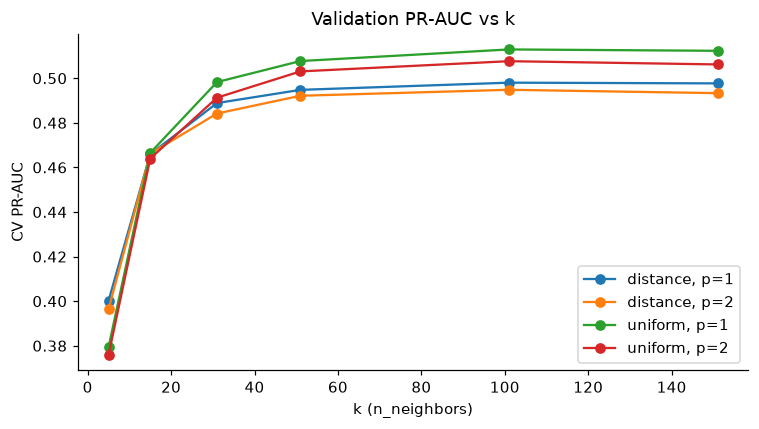

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
for (w, p), g in cv.groupby(["param_weights", "param_p"]):
    g = g.sort_values("param_n_neighbors")
    ax.plot(g["param_n_neighbors"].astype(int), g["mean_test_score"], marker="o", label=f"{w}, p={p}")
ax.set_xlabel("k (n_neighbors)")
ax.set_ylabel("CV PR-AUC")
ax.set_title("Validation PR-AUC vs k")
ax.legend()
plt.tight_layout()
plt.show()

Check for Overfitting / Underfitting 

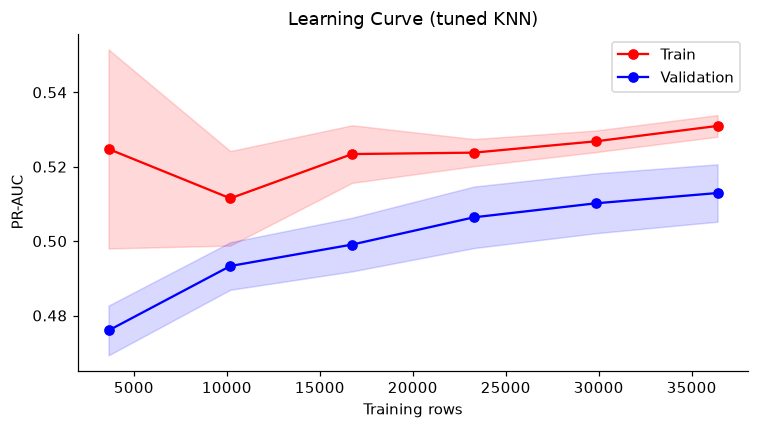

In [18]:
best_model = grid.best_estimator_
sizes, tr_sc, va_sc = learning_curve(best_model, X_train, y_train, cv=skf, scoring="average_precision",
                                     train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, random_state=RANDOM_STATE, shuffle=True)
fig, ax = plt.subplots(figsize=(7, 4))
for sc, label, color in [(tr_sc, "Train", "red"), (va_sc, "Validation", "blue")]:
    ax.plot(sizes, sc.mean(axis=1), marker="o", color=color, label=label)
    ax.fill_between(sizes, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1), color=color, alpha=.15)
ax.set_xlabel("Training rows")
ax.set_ylabel("PR-AUC")
ax.set_title("Learning Curve (tuned KNN)")
ax.legend()
plt.tight_layout()
plt.show()

In [19]:
oof = cross_val_predict(best_model, X_train, y_train, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
f1_oof, THRESHOLD = best_f1_threshold(y_train, oof)
print(f"Optimal F1 threshold from train CV:  {THRESHOLD:.3f}     (CV F1 = {f1_oof:.3f})")

Optimal F1 threshold from train CV:  0.228     (CV F1 = 0.508)


In [20]:
p_test = best_model.predict_proba(X_test)[:, 1]
def report(y, p, thr):
    pred = (p >= thr).astype(int)
    return {"threshold": thr, "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
            "F1": f1_score(y, pred), "accuracy": (pred == y).mean()}

final = pd.DataFrame({
    "threshold 0.5": report(y_test, p_test, 0.5),
    f"threshold {THRESHOLD:.2f} (CV f1-optimal)": report(y_test, p_test, THRESHOLD)
}).T

print(f"Test PR-AUC {average_precision_score(y_test, p_test):.3f}     Test ROC-AUC {roc_auc_score(y_test, p_test):.3f}")
final.round(3)

Test PR-AUC 0.434     Test ROC-AUC 0.848


,threshold,precision,recall,F1,accuracy
threshold 0.5,0.500,0.554,0.351,0.429,0.948
threshold 0.23 (CV f1-optimal),0.228,0.328,0.589,0.422,0.909


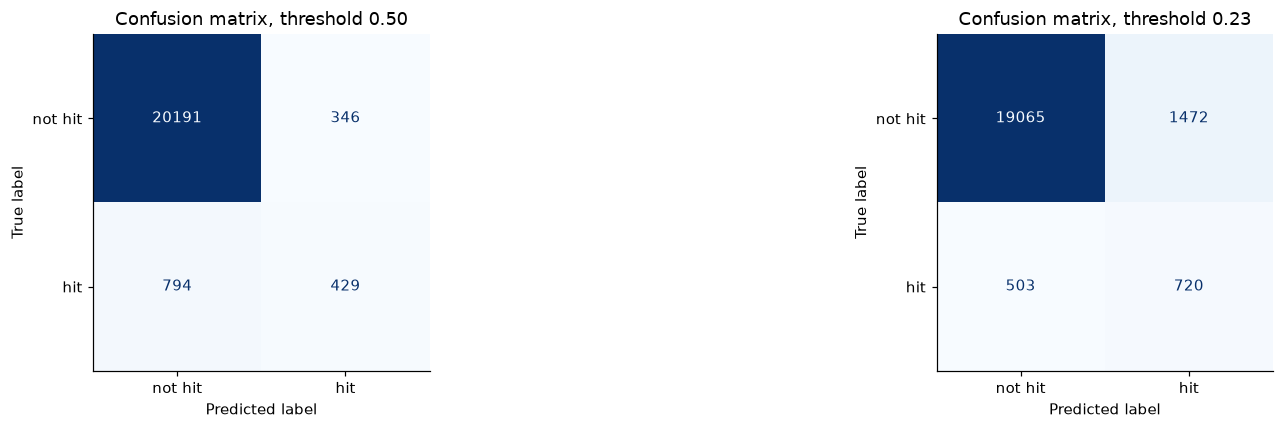

In [24]:
fig, axes = plt.subplots(1,2, figsize=(18,4))

for ax, thr in zip(axes, [0.5, THRESHOLD]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p_test >= thr).astype(int)), display_labels=["not hit", "hit"]).plot(ax=ax, colorbar=False, cmap="Blues",values_format="d")
    ax.set_title(f"Confusion matrix, threshold {thr:.2f}")
    ax.grid(False)
plt.tight_layout()
plt.show()

In [22]:
results = {
    "model": "knn",
    "preprocessing": "scaled data from preprocessing.ipynb, no class weighting (KNN has none), imbalance handled by CV threshold",
    "best_params": {k: v for k, v in grid.best_params_.items()},
    "cv_pr_auc": float(grid.best_score_),
    "test_pr_auc": float(average_precision_score(y_test, p_test)),
    "test_roc_auc": float(roc_auc_score(y_test, p_test)),
    "test_random_guesser_pr_auc": float(y_test.mean()), #what a random guesser would get
    "threshold_cv_f1_optimal": float(THRESHOLD),
    "test_at_0.5": {k: float(v) for k, v in report(y_test, p_test, 0.5).items()},
    "test_at_cv_threshold": {k: float(v) for k, v in report(y_test, p_test, THRESHOLD).items()},
}
with open(DATA_DIR / "knn_results.json", "w") as f:
    json.dump(results, f, indent=1, default=str)
print(json.dumps(results, indent=1, default=str))

{
 "model": "knn",
 "preprocessing": "scaled data from preprocessing.ipynb, no class weighting (KNN has none), imbalance handled by CV threshold",
 "best_params": {
  "n_neighbors": 101,
  "p": 1,
  "weights": "uniform"
 },
 "cv_pr_auc": 0.5129287762905486,
 "test_pr_auc": 0.43371965408646757,
 "test_roc_auc": 0.8482319030833246,
 "test_random_guesser_pr_auc": 0.05620404411764706,
 "threshold_cv_f1_optimal": 0.22772277227722773,
 "test_at_0.5": {
  "threshold": 0.5,
  "precision": 0.5535483870967742,
  "recall": 0.3507767784137367,
  "F1": 0.4294294294294294,
  "accuracy": 0.9476102941176471
 },
 "test_at_cv_threshold": {
  "threshold": 0.22772277227722773,
  "precision": 0.3284671532846715,
  "recall": 0.588716271463614,
  "F1": 0.4216691068814056,
  "accuracy": 0.9092371323529411
 }
}
